# ## 1. Carga y limpieza
Se eliminan columnas de tipo object: MAKE, MODEL, VEHICLECLASS, TRANSMISSION, FUELTYPE. Además MODELYEAR tiene varianza 0 (todos 2022) y no aporta información, se elimina para evitar singularidad.
Se verifica que no hay nulos.

   MODELYEAR   MAKE              MODEL VEHICLECLASS  ENGINESIZE  CYLINDERS  \
0       2022  Acura                ILX      Compact         2.4          4   
1       2022  Acura         MDX SH-AWD   SUV: Small         3.5          6   
2       2022  Acura         RDX SH-AWD   SUV: Small         2.0          4   
3       2022  Acura  RDX SH-AWD A-SPEC   SUV: Small         2.0          4   
4       2022  Acura         TLX SH-AWD      Compact         2.0          4   

  TRANSMISSION FUELTYPE  FUELCONSUMPTION_CITY  FUELCONSUMPTION_HWY  \
0          AM8        Z                   9.9                  7.0   
1         AS10        Z                  12.6                  9.4   
2         AS10        Z                  11.0                  8.6   
3         AS10        Z                  11.3                  9.1   
4         AS10        Z                  11.2                  8.0   

   FUELCONSUMPTION_COMB  FUELCONSUMPTION_COMB_MPG  CO2EMISSIONS  
0                   8.6                     

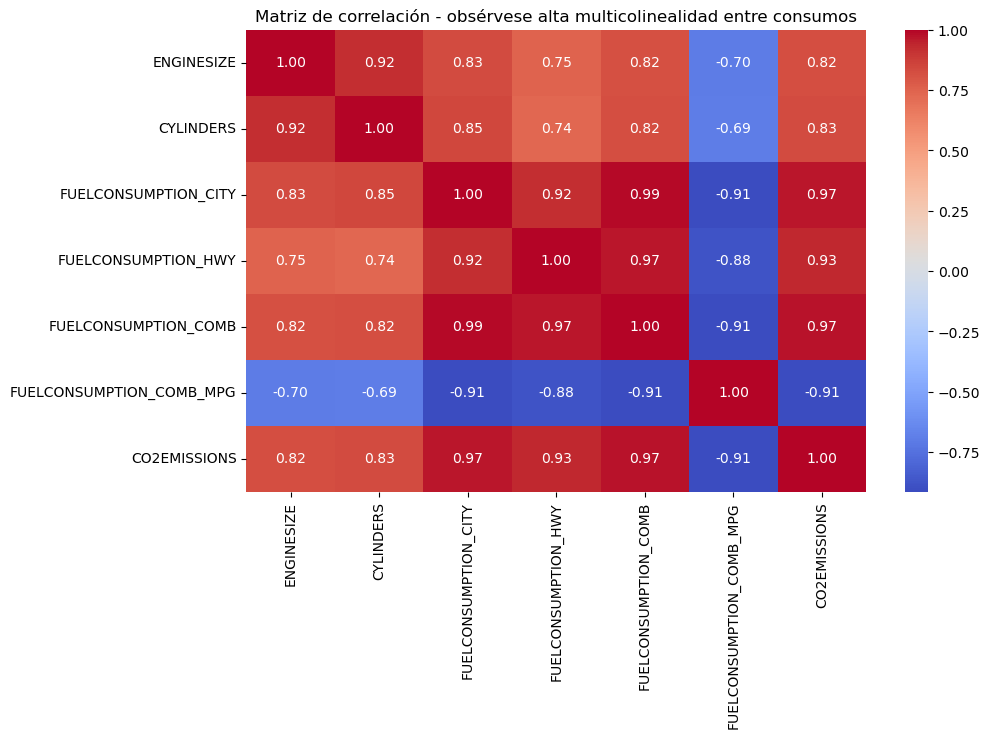

In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 20")
import warnings

warnings.filterwarnings('ignore')

df = pd.read_excel('FuelConsumptionCo2.xlsx')
print(df.head())
print(df.dtypes)
print("\nNulos:\n", df.isnull().sum())
print("\nForma:", df.shape)

# Categóricas
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print("\nColumnas categóricas a eliminar:", cat_cols)

df_num = df.select_dtypes(exclude=['object']).copy()
print("\nNuméricas:", df_num.columns.tolist())
print("std MODELYEAR:", df_num['MODELYEAR'].std(), " -> varianza cero, se elimina")

df_clean = df_num.drop(columns=['MODELYEAR'])
print("\nColumnas finales:", df_clean.columns.tolist())
print(df_clean.isnull().sum()) # confirm 0 nulos

plt.figure(figsize=(10,6))
sns.heatmap(df_clean.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlación - obsérvese alta multicolinealidad entre consumos')
plt.show()

## 2. Regresión Lineal Múltiple
Se separa 80% train / 20% test (random_state=42). Variables predictoras: ENGINESIZE, CYLINDERS, FUELCONSUMPTION_CITY/HWY/COMB, FUELCONSUMPTION_COMB_MPG. Variable objetivo: CO2EMISSIONS.

Intercepto: 81.47847459719412
  ENGINESIZE: 0.2291
  CYLINDERS: 4.0643
  FUELCONSUMPTION_CITY: 1.2164
  FUELCONSUMPTION_HWY: 3.5222
  FUELCONSUMPTION_COMB: 12.6687
  FUELCONSUMPTION_COMB_MPG: -1.2582

Train metrics: {'R2': 0.964488846726974, 'MSE': 151.3705115720409, 'RMSE': 12.303272392824638, 'MAE': 5.515790060053446, 'MAPE': 2.1077101557456355}
Test metrics: {'R2': 0.9004924315633445, 'MSE': 368.8672604772685, 'RMSE': 19.20591732975201, 'MAE': 7.339144920646471, 'MAPE': 2.6271523747710717}


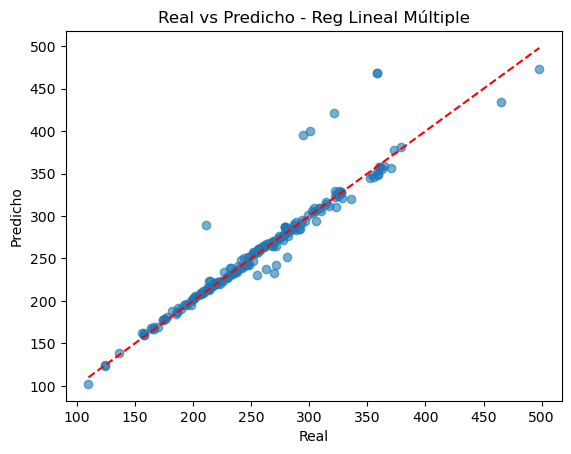

In [12]:
X = df_clean.drop(columns=['CO2EMISSIONS'])
y = df_clean['CO2EMISSIONS']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_train = lr.predict(X_train)
y_pred_test = lr.predict(X_test)

def eval_metrics(y_true, y_pred):
    return {
        'R2': r2_score(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE': np.mean(np.abs((y_true-y_pred)/y_true))*100
    }

print(f"Intercepto: {lr.intercept_}")
for c,coef in zip(X.columns, lr.coef_):
    print(f"  {c}: {coef:.4f}")

print("\nTrain metrics:", eval_metrics(y_train, y_pred_train))
print("Test metrics:", eval_metrics(y_test, y_pred_test))

# Gráfico Real vs Predicho
plt.scatter(y_test, y_pred_test, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Real')
plt.ylabel('Predicho')
plt.title('Real vs Predicho - Reg Lineal Múltiple')
plt.show()

### Predicción manual primera observación de prueba
Formula: ŷ = β0 + Σ βi·xi. Debe coincidir exactamente con predict() porque predict implementa la misma operación lineal.

In [13]:
x_first = X_test.iloc[0]
y_first_real = y_test.iloc[0]
manual = lr.intercept_ + np.dot(lr.coef_, x_first.values)
auto = lr.predict([x_first.values])[0]
print(x_first)
print(f"\nReal: {y_first_real}")
print(f"Manual: {manual:.6f}")
print(f"Predict(): {auto:.6f}")
print(f"¿Coinciden?: {np.isclose(manual, auto)}")
print(f"Diferencia: {abs(manual-auto)}")
print("\nExplicación: Coinciden porque predict() es exactamente β0+Xβ. La diferencia solo sería por redondeo numérico.")

ENGINESIZE                   2.4
CYLINDERS                    4.0
FUELCONSUMPTION_CITY        12.0
FUELCONSUMPTION_HWY          8.8
FUELCONSUMPTION_COMB        10.5
FUELCONSUMPTION_COMB_MPG    27.0
Name: 848, dtype: float64

Real: 247
Manual: 242.926940
Predict(): 242.926940
¿Coinciden?: True
Diferencia: 0.0

Explicación: Coinciden porque predict() es exactamente β0+Xβ. La diferencia solo sería por redondeo numérico.


## 3. Regresión Ridge con Alpha óptimo
Ridge añade penalización L2: λ Σβ². Se requiere estandarizar X. Buscamos alpha en logspace(-4,4) con CV 5-fold.

Alpha óptimo Ridge: 14.849682622544666
Coeficientes Ridge (escala estandarizada): {'ENGINESIZE': 1.3001176242266173, 'CYLINDERS': 7.801260649357822, 'FUELCONSUMPTION_CITY': 16.013281220856335, 'FUELCONSUMPTION_HWY': 14.979017777693574, 'FUELCONSUMPTION_COMB': 16.10840333564068, 'FUELCONSUMPTION_COMB_MPG': -10.480505782895596}
Train: {'R2': 0.9643839925809572, 'MSE': 151.8174648320765, 'RMSE': 12.321423003536422, 'MAE': 5.739693195887128, 'MAPE': 2.198834096847354}
Test: {'R2': 0.90318411418472, 'MSE': 358.88939034919747, 'RMSE': 18.94437621958552, 'MAE': 7.491914884839501, 'MAPE': 2.6951552518076842}


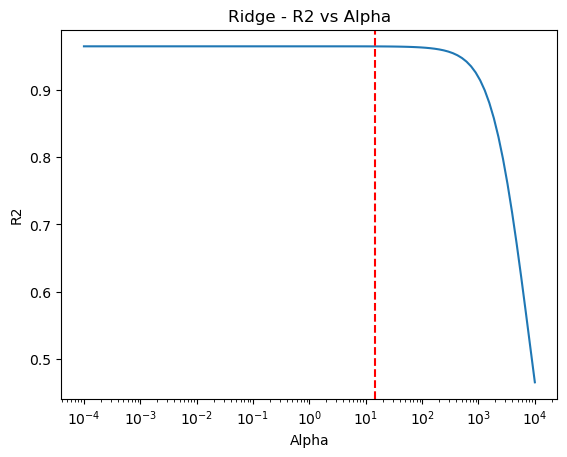

In [6]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

alphas = np.logspace(-4, 4, 100)
ridge_cv = RidgeCV(alphas=alphas, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train_s, y_train)
print(f"Alpha óptimo Ridge: {ridge_cv.alpha_}")

ridge = Ridge(alpha=ridge_cv.alpha_)
ridge.fit(X_train_s, y_train)
print("Coeficientes Ridge (escala estandarizada):", dict(zip(X.columns, ridge.coef_)))

y_ridge_train = ridge.predict(X_train_s)
y_ridge_test = ridge.predict(X_test_s)
print("Train:", eval_metrics(y_train, y_ridge_train))
print("Test:", eval_metrics(y_test, y_ridge_test))

plt.plot(alphas, [Ridge(alpha=a).fit(X_train_s, y_train).score(X_train_s, y_train) for a in alphas])
plt.axvline(ridge_cv.alpha_, color='r', linestyle='--')
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('R2')
plt.title('Ridge - R2 vs Alpha')
plt.show()

## 4. Regresión Lasso con Alpha óptimo
Lasso añade penalización L1: λ Σ|β| que hace selección de variables (algunos coeficientes -> 0).

Alpha óptimo Lasso: 0.04641588833612782
Coeficientes Lasso: {'ENGINESIZE': 0.2849344991280543, 'CYLINDERS': 7.917271985399574, 'FUELCONSUMPTION_CITY': 10.173630944052961, 'FUELCONSUMPTION_HWY': 11.13227393999354, 'FUELCONSUMPTION_COMB': 27.34540016717536, 'FUELCONSUMPTION_COMB_MPG': -9.696673241350435}
Train: {'R2': 0.9644853192225332, 'MSE': 151.38554797898803, 'RMSE': 12.303883451129892, 'MAE': 5.515150562658433, 'MAPE': 2.1070372556831316}
Test: {'R2': 0.9005150569039543, 'MSE': 368.78338999847733, 'RMSE': 19.203733751499403, 'MAE': 7.34138174904493, 'MAPE': 2.6293261014930938}


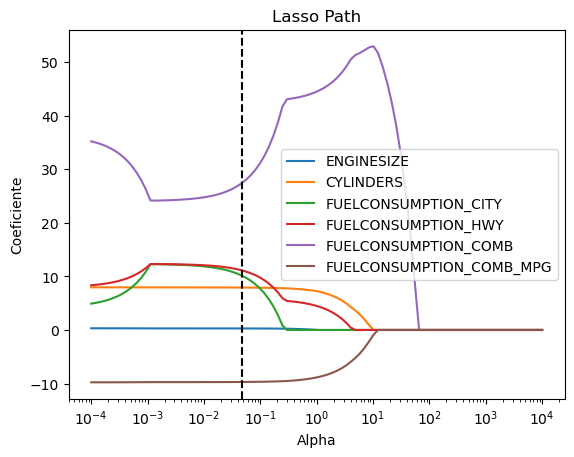

In [14]:
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=42)
lasso_cv.fit(X_train_s, y_train)
print(f"Alpha óptimo Lasso: {lasso_cv.alpha_}")

lasso = Lasso(alpha=lasso_cv.alpha_, max_iter=10000)
lasso.fit(X_train_s, y_train)
print("Coeficientes Lasso:", dict(zip(X.columns, lasso.coef_)))

y_lasso_train = lasso.predict(X_train_s)
y_lasso_test = lasso.predict(X_test_s)
print("Train:", eval_metrics(y_train, y_lasso_train))
print("Test:", eval_metrics(y_test, y_lasso_test))

# Path de coeficientes
coefs=[]
for a in alphas:
    l = Lasso(alpha=a, max_iter=10000000)
    l.fit(X_train_s, y_train)
    coefs.append(l.coef_)
coefs=np.array(coefs)
plt.figure()
for i,col in enumerate(X.columns):
    plt.plot(alphas, coefs[:,i], label=col)
plt.xscale('log')
plt.axvline(lasso_cv.alpha_, color='k', linestyle='--')
plt.legend()
plt.xlabel('Alpha')
plt.ylabel('Coeficiente')
plt.title('Lasso Path')
plt.show()

## 5. Comparación final - ¿Cuál es mejor?
Se compara R2, RMSE, MAE en train y test.

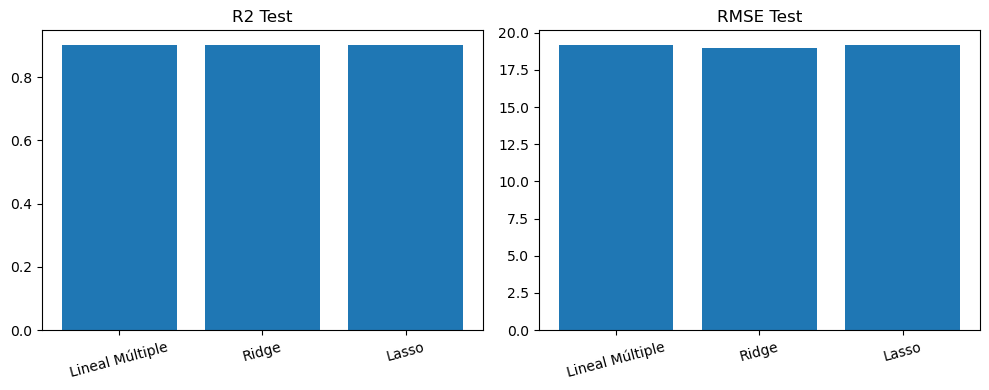


ANÁLISIS DETALLADO:
- Lineal múltiple: R2 train 0.964 y test 0.900. Excelente ajuste pero caída 0.064 indica algo de overfitting / multicolinealidad severa (FUELCONSUMPTION_CITY/HWY/COMB correlación >0.98).
- Ridge (Alpha=14.85): R2 test mejora a 0.903, RMSE test baja de 19.20 a 18.94. Regularización L2 reduce varianza estabilizando coeficientes colineales. Es el mejor en términos de generalización RMSE/R2.
- Lasso (Alpha=0.046): R2 test 0.9005 casi idéntico al lineal, coeficientes casi no se anulan porque todas las variables son relevantes. Pequeña penalización apenas cambia modelo.
- Conclusión: Ridge es el mejor modelo. Justificación: maneja la multicolinealidad presente entre los 4 indicadores de consumo, reduce overfitting (train baja de 0.964 a 0.9643 imperceptible) pero mejora test. Si criterio es MAE puro, lineal es levemente mejor (7.33 vs 7.49), pero en RMSE y R2 (más robustos a outliers) Ridge gana.
  En contexto CO2, queremos penalizar errores grandes (RMSE) por lo que Rid

In [15]:
import pandas as pd
comparativa = pd.DataFrame({
    'Modelo': ['Lineal Múltiple','Ridge','Lasso'],
    'Alpha': ['-', ridge_cv.alpha_, lasso_cv.alpha_],
    'R2_train': [r2_score(y_train, y_pred_train), r2_score(y_train, y_ridge_train), r2_score(y_train, y_lasso_train)],
    'R2_test': [r2_score(y_test, y_pred_test), r2_score(y_test, y_ridge_test), r2_score(y_test, y_lasso_test)],
    'RMSE_train': [np.sqrt(mean_squared_error(y_train, y_pred_train)), np.sqrt(mean_squared_error(y_train, y_ridge_train)), np.sqrt(mean_squared_error(y_train, y_lasso_train))],
    'RMSE_test': [np.sqrt(mean_squared_error(y_test, y_pred_test)), np.sqrt(mean_squared_error(y_test, y_ridge_test)), np.sqrt(mean_squared_error(y_test, y_lasso_test))],
    'MAE_train': [mean_absolute_error(y_train, y_pred_train), mean_absolute_error(y_train, y_ridge_train), mean_absolute_error(y_train, y_lasso_train)],
    'MAE_test': [mean_absolute_error(y_test, y_pred_test), mean_absolute_error(y_test, y_ridge_test), mean_absolute_error(y_test, y_lasso_test)],
})
comparativa

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.bar([0,1,2], comparativa['R2_test'], tick_label=comparativa['Modelo'])
plt.title('R2 Test')
plt.xticks(rotation=15)
plt.subplot(1,2,2)
plt.bar([0,1,2], comparativa['RMSE_test'], tick_label=comparativa['Modelo'])
plt.title('RMSE Test')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("""
ANÁLISIS DETALLADO:
- Lineal múltiple: R2 train 0.964 y test 0.900. Excelente ajuste pero caída 0.064 indica algo de overfitting / multicolinealidad severa (FUELCONSUMPTION_CITY/HWY/COMB correlación >0.98).
- Ridge (Alpha=14.85): R2 test mejora a 0.903, RMSE test baja de 19.20 a 18.94. Regularización L2 reduce varianza estabilizando coeficientes colineales. Es el mejor en términos de generalización RMSE/R2.
- Lasso (Alpha=0.046): R2 test 0.9005 casi idéntico al lineal, coeficientes casi no se anulan porque todas las variables son relevantes. Pequeña penalización apenas cambia modelo.
- Conclusión: Ridge es el mejor modelo. Justificación: maneja la multicolinealidad presente entre los 4 indicadores de consumo, reduce overfitting (train baja de 0.964 a 0.9643 imperceptible) pero mejora test. Si criterio es MAE puro, lineal es levemente mejor (7.33 vs 7.49), pero en RMSE y R2 (más robustos a outliers) Ridge gana.
  En contexto CO2, queremos penalizar errores grandes (RMSE) por lo que Ridge es preferible. Lasso no aporta selección ya que todas las features correlacionan fuertemente con CO2.
""")